# P2 · Riesgo de vaciado o llenado de estaciones MiBici

**Proyecto:** TC5061 · Equipo 37
**Autor:** Mario González
**Pregunta:** ¿una estación estará en riesgo de quedarse sin bicicletas o sin anclajes en las próximas 2 horas?


## 0. Configuración

In [1]:
import gc
import warnings
import hashlib
import re
import subprocess
import mlflow
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


from pathlib import Path
from IPython.display import display
from matplotlib.patches import FancyBboxPatch
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, brier_score_loss, fbeta_score, precision_recall_curve
from MiBici.config import MLFLOW_ARTIFACT_DIR, MLFLOW_EXPERIMENT, MLFLOW_TRACKING_URI

pd.set_option("display.max_columns", 50)
warnings.filterwarnings("ignore", message="Mean of empty slice")

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RAW = ROOT / "data" / "raw"
OUT = ROOT / "data" / "processed" / "p2"
FIG = ROOT / "reports" / "figures" / "p2"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

# Parámetros del run (se registrarán en MLflow)
P = {
    "fecha_inicio": "2024-01-01",
    "fecha_fin": "2025-12-30",
    "train_fin": "2025-06-30",
    "val_fin": "2025-09-30",
    "hora_reinicio": 5, # hora de reinicio del día operativo (05:00)
    "dur_max_h": 24,
    "empates": "neto", # cómo resolver empates de eventos en el mismo segundo: "neto" (vaciado) o "aleatorio"
    "s0_metodo": "factible_por_estacion", # cómo reconstruir el inventario inicial: "factible_por_estacion" (por estación)
    "min_dias_s0": 30,
    "umbral_vacio": 0.10,
    "umbral_lleno": 0.90,
    "horizonte_h": 2, # horizonte de predicción en horas
    "resolucion_min": 15,
    "k_visitas": 20, # número de visitas que se pueden hacer por hora
    "seed": 37,
}
CLASES = ["normal", "vaciado", "llenado"]
T5 = pd.Timedelta(hours=P["hora_reinicio"])

/home/mario/.pyenv/versions/mibici/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-18 13:07:36.882 | INFO     | MiBici.config:<module>:11 - PROJ_ROOT path is: /home/mario/code/maestria/4to Trimestre/MLOps/proyecto/TC5061-Proyecto-Equipo37


## 1. Definición de los datos

### 1.1 Rango de fechas: enero 2024 – diciembre 2025

- **Dos años completos.** La demanda tiene estacionalidad anual (vacaciones, temporada de lluvias de junio a septiembre, diciembre). Con dos años, el periodo de entrenamiento ve cada mes al menos una vez y validación y prueba caen en meses que ya se vieron un año antes.
- **Cantidad de datos:** Sufucuentes para tener un modelo robusto pero sin necesidad de procesamiento excesivo.


### 1.2 Fuente

[Datos abiertos de MiBici](https://www.mibici.net/es/datos-abiertos/), publicados por la Agencia Metropolitana de Servicios de Infraestructura para la Movilidad del AMG.

Los 24 archivos mensuales se consolidaron en `data/raw/mibici_2024_2025.csv` con encabezados normalizados. 

**Limitación de la nomenclatura:** es la única versión publicada y es de septiembre de 2026, posterior al rango. Si alguna estación cambió de capacidad entre 2024 y 2026, Cₛ sería incorrecta para esos días. Se verifica abajo que todas las estaciones con viajes aparezcan en el catálogo.

### 1.3 Tamaño real obtenido

In [2]:
# Solo se cargan las columnas que usa P2: los datos personales se quedan fuera desde la lectura
trips = pd.read_csv(
    RAW / "mibici_2024_2025.csv",
    usecols=["Viaje_Id", "Inicio_del_viaje", "Fin_del_viaje", "Origen_Id", "Destino_Id"],
    dtype={"Viaje_Id": "int64", "Origen_Id": "int32", "Destino_Id": "int32"},
    parse_dates=["Inicio_del_viaje", "Fin_del_viaje"],
    engine="pyarrow",
)
stations = pd.read_csv(RAW / "nomenclatura_2026_09.csv")

ids_viajes = set(trips["Origen_Id"]) | set(trips["Destino_Id"])
tamano = pd.Series({
    "meses": trips["Inicio_del_viaje"].dt.to_period("M").nunique(),
    "primer viaje": trips["Inicio_del_viaje"].min(),
    "último viaje": trips["Inicio_del_viaje"].max(),
    "viajes (crudo)": len(trips),
    "Viaje_Id duplicados": trips["Viaje_Id"].duplicated().sum(),
    "estaciones con viajes": len(ids_viajes),
    "estaciones en nomenclatura": len(stations),
    "estaciones con viajes sin capacidad": len(ids_viajes - set(stations["id"])),
}, name="valor")
tamano.to_frame()

,valor
meses,24
primer viaje,2024-01-01 00:05:25
último viaje,2025-12-31 23:59:08
viajes (crudo),9177953
Viaje_Id duplicados,0
estaciones con viajes,373
estaciones en nomenclatura,484
estaciones con viajes sin capacidad,0


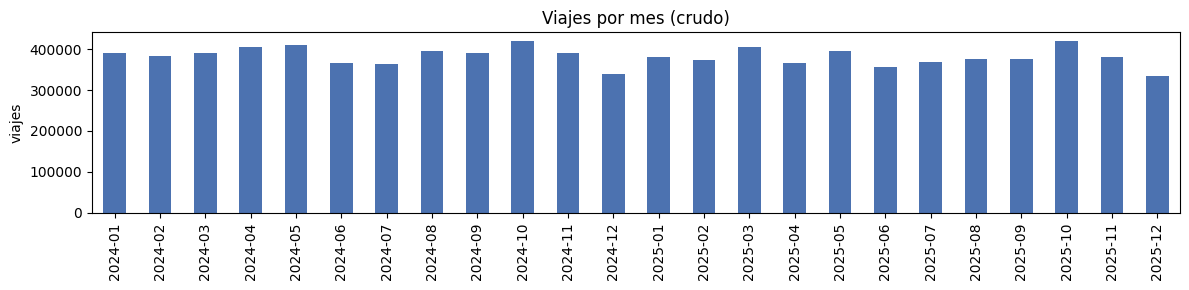

In [3]:
viajes_mes = trips.groupby(trips["Inicio_del_viaje"].dt.to_period("M")).size()
ax = viajes_mes.plot(kind="bar", figsize=(12, 3), color="#4C72B0")
ax.set(title="Viajes por mes (crudo)", xlabel="", ylabel="viajes")
plt.tight_layout()

### 1.4 Variables originales y construcción de la variable objetivo

Variables que usaremos para reconstruir el inventario, generar la etiqueta de riesgo y entrenar el modelo:

| Variable original | Uso |
|---|---|
| Inicio_del_viaje, Origen_Id | Evento de salida (−1) en la estación de origen |
| Fin_del_viaje, Destino_Id | Evento de llegada (+1) en la estación de destino |
| Viaje_Id | Control de duplicados |
| id, dpcapacity, latitude, longitude (nomenclatura) | Capacidad Cₛ y ubicación de cada estación |

Usuario_Id, Genero y Año_de_nacimiento no se cargan, no son relevantes para este análisis.

Variable objetivo: clase_riesgo_2h ∈ {normal, vaciado, llenado}

Los datos no traen el inventario de las estaciones, así que se reconstruye con los viajes y la capacidad:

1. **Eventos.** Cada viaje genera una salida y una llegada. A cada evento se le asigna su propio día operativo (`ts − 5 h`; el servicio va de 05:00 a 00:59).
2. **Empates.** Los eventos de una estación en el mismo segundo se suman como un solo cambio neto. Así no se inventa un pico que no se puede comprobar con resolución de 1 s.
3. **Cotas por estación y día.** Con el acumulado del día: `L = −min(acum, 0)` y `U = Cₛ − max(acum, 0)`. Cualquier inventario inicial s con L ≤ s ≤ U hace posible el día. Si L > U hubo rebalanceo diurno y el día es **infactible**.
4. **ŝ₀ por estación** (solo con entrenamiento): el s ∈ [0, Cₛ] factible en el mayor % de días. Empate → el más cercano a Cₛ/2, y si quedan a la misma distancia, el menor. Estaciones con menos de 30 días de entrenamiento → ⌊Cₛ/2⌋.
5. **Inventario reconstruido** (solo para la etiqueta): parte de `s₀ = clip(ŝ₀, L, U)` del día y se le suma el acumulado. En cada intervalo de 15 min se guarda el **mínimo y el máximo**, no solo el valor al cierre.
6. **Estado por intervalo:** vacío si la ocupación mínima ≤ 0.10, lleno si la máxima ≥ 0.90.
7. **Etiqueta para la predicción en t:** se revisan los 8 intervalos que inician en t, t+15, …, t+105. Si alguno está vacío → vaciado; si alguno está lleno → llenado; si aparecen ambos, gana el primero. No se usa `shift(-8)`: interesa si pasa en algún momento de la ventana.
8. Las filas de modelado son las horas en punto de 05:00 a 00:00 de cada día factible.

#### Limpieza

In [4]:
dur = (trips["Fin_del_viaje"] - trips["Inicio_del_viaje"]).dt.total_seconds()
misma = trips["Origen_Id"] == trips["Destino_Id"]
reglas = {
    "duración negativa": dur < 0,
    "duración 0 s": dur == 0,
    "< 1 min entre estaciones distintas": (dur > 0) & (dur < 60) & ~misma,
    f"> {P['dur_max_h']} h": dur > P["dur_max_h"] * 3600,
    "estación fuera del catálogo": ~trips["Origen_Id"].isin(stations["id"]) | ~trips["Destino_Id"].isin(stations["id"]),
}
quitar = np.logical_or.reduce(list(reglas.values()))
display(pd.Series({k: int(v.sum()) for k, v in reglas.items()} | {"total eliminado": int(quitar.sum())}, name="viajes").to_frame())

trips = trips.loc[~quitar].reset_index(drop=True)
print(f"viajes después de limpiar: {len(trips):,}")
del dur, misma, reglas, quitar

,viajes
duración negativa,0
duración 0 s,23630
< 1 min entre estaciones distintas,9829
> 24 h,19
estación fuera del catálogo,0
total eliminado,33478


viajes después de limpiar: 9,144,475


Los viajes de menos de 1 min a la misma estación se conservan: son bicis que se desanclan y se vuelven a anclar, su efecto neto es 0 y no mueven las cotas. Los viajes largos (hasta 24 h) también se conservan, porque su salida y su llegada sí ocurrieron; con el día operativo asignado por evento, cada uno cae en su día.

#### Eventos, empates y cotas por estación-día

In [5]:
n = len(trips)
# Ponemos todos los eventos de salida primero y despues los de llegaga
# para armar el DataFrame de eventos con un solo cambio neto por estación y segundo
ev = pd.DataFrame({
    "estacion": np.concatenate([trips["Origen_Id"].values, trips["Destino_Id"].values]),
    "ts": np.concatenate([trips["Inicio_del_viaje"].values, trips["Fin_del_viaje"].values]),
    "salida": np.concatenate([np.ones(n, "int8"), np.zeros(n, "int8")]),
})
ev["llegada"] = (1 - ev["salida"]).astype("int8")

# Eliminamos trips para limpiar la memoria y a partir de aquí todo se calcula con los eventos
del trips  

# Dia operativo
ev["dia"] = (ev["ts"] - T5).dt.normalize()

ev = ev[ev["dia"].between(P["fecha_inicio"], P["fecha_fin"])]
print(f"eventos: {len(ev):,}")

# Empates: un solo cambio neto por estación y segundo
ev = ev.groupby(["estacion", "dia", "ts"], sort=True)[["salida", "llegada"]].sum().reset_index()
ev["delta"] = (ev["llegada"] - ev["salida"]).astype("int16")
print(f"filas después de agregar empates: {len(ev):,}")

# Columna de estacion-dia para poder hacer la suma acumulativa de delta por estacion y dia
ev["sd"] = ev.groupby(["estacion", "dia"], sort=True).ngroup()
ev["acum"] = ev.groupby("sd")["delta"].cumsum()

eventos: 18,274,498
filas después de agregar empates: 17,929,590


In [6]:
# Traemos la capacidad de cada estacion y agrupamos las cotas de 
# cada estación-día: mínimo, máximo, L, U y factibilidad
cap = stations.set_index("id")["dpcapacity"]
cotas = ev.groupby("sd").agg(
    estacion=("estacion", "first"),
    dia=("dia", "first"),
    total=("delta", "sum"),
    minimo=("acum", "min"),
    maximo=("acum", "max"),
    eventos=("delta", "size"),
)

cotas["minimo"] = cotas["minimo"].clip(upper=0)
cotas["maximo"] = cotas["maximo"].clip(lower=0)
cotas["C"] = cotas["estacion"].map(cap).astype(int)
cotas["L"] = -cotas["minimo"]
cotas["U"] = cotas["C"] - cotas["maximo"]
cotas["infactible"] = cotas["L"] > cotas["U"]

# Columna para marcar si son de train, val o test según la fecha del día operativo
cotas["particion"] = np.select([cotas["dia"] <= P["train_fin"], cotas["dia"] <= P["val_fin"]], ["train", "val"], "test")
print(f"estación-días con eventos: {len(cotas):,}")
cotas.groupby("particion")["infactible"].agg(["size", "mean"]).rename(columns={"size": "estacion_dias", "mean": "% infactibles"})

estación-días con eventos: 265,128


,estacion_dias,% infactibles
particion,,
test,33379,0.139429
train,198013,0.176458
val,33736,0.157903


Solo se modelan estación-días **con al menos un evento**. Un día sin eventos es trivialmente factible, pero no se puede distinguir si la estación tuvo cero demanda o estuvo cerrada, así que no aporta una etiqueta confiable.

#### ŝ₀ por estación (solo entrenamiento)

In [7]:
cotas

,estacion,dia,total,minimo,maximo,eventos,C,L,U,infactible,particion
sd,,,,,,,,,,,
0,2,2024-01-01,-2,-7,1,43,15,7,14,False,train
1,2,2024-01-02,2,-12,2,193,15,12,13,False,train
2,2,2024-01-03,2,-11,3,207,15,11,12,False,train
3,2,2024-01-04,7,-12,9,203,15,12,6,True,train
4,2,2024-01-05,14,-7,15,212,15,7,0,True,train
...,...,...,...,...,...,...,...,...,...,...,...
265123,402,2025-12-26,1,0,3,11,19,0,16,False,test
265124,402,2025-12-27,1,0,1,5,19,0,18,False,test
265125,402,2025-12-28,-3,-3,0,5,19,3,19,False,test


In [8]:
def calcular_s0(c_train, todas, min_dias):
    filas = []
    for estacion, g in c_train.groupby("estacion"):
        # capacidad
        C = int(g["C"].iloc[0])
        # valores de s posibles: 0, 1, ..., C
        s = np.arange(C + 1)

        # Contamos cuántos días de entrenamiento son factibles para cada valor de s
        cnt = ((g["L"].values[:, None] <= s) & (s <= g["U"].values[:, None])).sum(0)
        if len(g) >= min_dias:
            # Si la estacion tiene mas de min dias lo guardamos en s0, el valor mas cercano a C/2
            # Guardamos tambien el metodo usado
            candidatos = s[cnt == cnt.max()]
            s0, metodo = int(candidatos[np.argmin(np.abs(candidatos - C / 2))]), "max_factible"
        else:
            s0, metodo = C // 2, "fallback_cs2"

        # Lo guardamos para despues convertirlo en DF
        filas.append((estacion, C, len(g), s0, metodo, cnt[s0] / len(g), cnt[C // 2] / len(g)))

    out = pd.DataFrame(filas, columns=["estacion", "C", "dias_train", "s0", "metodo", "pct_factible_s0", "pct_factible_cs2"])
    # Buscamos estaciones sin datos de entrenamiento y les asignamos s0 = C/2
    faltan = sorted(set(todas) - set(out["estacion"]))
    extra = pd.DataFrame({"estacion": faltan, "C": [int(cap[e]) for e in faltan], "dias_train": 0})
    extra["s0"], extra["metodo"] = extra["C"] // 2, "fallback_cs2"
    return pd.concat([out, extra], ignore_index=True).set_index("estacion")

# Le passamos solo los dias de train
s0_est = calcular_s0(cotas[cotas["particion"] == "train"], cotas["estacion"].unique(), P["min_dias_s0"])
# Guardamos el resultado en un CSV para usarlo en la siguiente etapa
s0_est.to_csv(OUT / "s0_por_estacion.csv")
display(s0_est["metodo"].value_counts().to_frame())
s0_est.describe().round(2)

,count
metodo,
max_factible,370
fallback_cs2,3


,C,dias_train,s0,pct_factible_s0,pct_factible_cs2
count,373.00,373.00,373.00,371.00,371.00
mean,16.94,530.87,8.84,0.67,0.58
std,4.15,76.09,3.66,0.29,0.31
min,11.00,0.00,1.00,0.03,0.01
25%,15.00,547.00,7.00,0.39,0.31
50%,15.00,547.00,9.00,0.74,0.60
75%,19.00,547.00,11.00,0.95,0.89
max,39.00,547.00,32.00,1.00,1.00


**Validación.** En entrenamiento ŝ₀ es óptimo por construcción, así que la comparación honesta es en validación: ¿en qué % de los días de validación el ŝ₀ calculado con entrenamiento sigue siendo factible, comparado con ⌊Cₛ/2⌋?

In [9]:
cv = cotas[cotas["particion"] == "val"].join(s0_est["s0"], on="estacion")
proxy = pd.Series({
    "% días val factibles con ŝ₀": ((cv["L"] <= cv["s0"]) & (cv["s0"] <= cv["U"])).mean(),
    "% días val factibles con ⌊Cₛ/2⌋": ((cv["L"] <= cv["C"] // 2) & (cv["C"] // 2 <= cv["U"])).mean(),
    "% días val infactibles (L > U)": cv["infactible"].mean(),
    "estaciones con % factible ŝ₀ < 50 % (train)": int((s0_est["pct_factible_s0"] < 0.5).sum()),
}).round(3)
proxy.to_frame("valor")

,valor
% días val factibles con ŝ₀,0.671
% días val factibles con ⌊Cₛ/2⌋,0.604
% días val infactibles (L > U),0.158
estaciones con % factible ŝ₀ < 50 % (train),128.000


**Resultados de la validación**

- **ŝ₀ supera a ⌊Cₛ/2⌋ fuera de entrenamiento.** En validación, el ŝ₀ calculado solo con entrenamiento hace factible el 67.1 % de los días, contra 60.4 % con la mitad de la capacidad. Las estaciones sí tienen un inventario inicial típico, distinto del punto medio, y ese patrón se mantiene en meses que ŝ₀ no vio.
- **Rebalanceo durante el día.** El 15.8 % de los días de validación son infactibles: ningún inventario inicial explica sus viajes sin agregar o retirar bicis durante el día. Lo más probable es que se trate de rebalanceo diurno, aunque también podría deberse a una capacidad incorrecta en la nomenclatura (que es de 2026), a bicis retiradas para mantenimiento o a viajes no registrados. Los datos no registran el rebalanceo, así que no se puede usar como feature: no sabemos cuándo ocurre ni cuántas bicis mueve. Además, el rebalanceo es la decisión que el modelo busca apoyar, por lo que usarlo como entrada sería circular. Lo que sí se hace es descartar los días infactibles de la etiqueta.


**Qué implica para el modelo**

- **Features:** cuando ŝ₀ no es factible en un día, el inventario estimado se sale de [0, Cₛ]. Se deja así: un valor fuera de rango también le indica al modelo que el día es atípico.
- **Etiqueta:** en los días factibles, el inventario reconstruido parte de clip(ŝ₀, L, U), que siempre es factible, así que la etiqueta está bien definida aunque ŝ₀ no lo sea. Los días infactibles se descartan.
- **Limitación:** no hay datos de inventario real para comparar, así que esta validación solo mide qué tan coherente es el proxy con los viajes, no qué tan cerca está del inventario verdadero. Las métricas del modelo se deben leer como **qué tan bien predice el riesgo reconstruido**.


#### Inventario reconstruido en una malla de 15 minutos y etiqueta

In [10]:
# 96 intervalos por día (05:00 → 05:00)
NI = 24 * 60 // P["resolucion_min"]       
# numero de estacion-días    
n_sd = len(cotas)
# Creamos intervalos de P["resolucion_min"] (15 min) y asignamos un índice a cada intervalo de cada estacion-dia
k = ((ev["ts"] - ev["dia"] - T5) // pd.Timedelta(minutes=P["resolucion_min"])).to_numpy().astype(int)
# creamos un indice para cada evento en intervalos de cada estacion-dia
flat = ev["sd"].to_numpy() * NI + k

# Convertimos flat en una matriz de n_sd filas y NI columnas, donde cada celda contiene la suma de los deltas de los eventos que caen en ese intervalo
net = np.bincount(flat, weights=ev["delta"], minlength=n_sd * NI).reshape(n_sd, NI).astype("int32")
# acumulado al cierre de cada intervalo
fin = net.cumsum(axis=1)                       
# acumulado al inicio de cada intervalo
ini = fin - net                                

extremos = pd.DataFrame({"f": flat, "a": ev["acum"].to_numpy()}).groupby("f")["a"].agg(["min", "max"])
# Extraemos los maximos y mínimos de cada intervalo de cada estacion-dia, seleccionando entre el inicio
# o el acumulado al cierre del intervalo
ev_min = ini.ravel().copy() 
ev_max = ini.ravel().copy()
ev_min[extremos.index] = np.minimum(ev_min[extremos.index], extremos["min"].to_numpy())
ev_max[extremos.index] = np.maximum(ev_max[extremos.index], extremos["max"].to_numpy())
acum_min, acum_max = ev_min.reshape(n_sd, NI), ev_max.reshape(n_sd, NI)

# Borramos variables intermedias para liberar memoria
del  fin, net, k, extremos, flat

C = cotas["C"].to_numpy()
# s0 con todos los valores de train
s0_hat = cotas["estacion"].map(s0_est["s0"]).to_numpy()
# s0 ajustado al dia, solo lo aplicamos en dias factibles
s0_adj = np.clip(s0_hat, cotas["L"].to_numpy(), cotas["U"].to_numpy())  
# invertimos la columna de infactibles para poder filtrar los días factibles
fact = ~cotas["infactible"].to_numpy()

occ_min = (s0_adj[:, None] + acum_min) / C[:, None]
occ_max = (s0_adj[:, None] + acum_max) / C[:, None]
assert (occ_min[fact] >= 0).all() and (occ_max[fact] <= 1).all(), "el inventario reconstruido se sale de [0, Cₛ]"

# Desde estas matrices obtendremos la etiqueta de vacío y lleno
vacio = occ_min <= P["umbral_vacio"]
lleno = occ_max >= P["umbral_lleno"]
del ev_min, ev_max, acum_min, acum_max, occ_min, occ_max
print("intervalos con vacío y lleno a la vez (días factibles, dias que U > L):", int((vacio & lleno)[fact].sum()))
print("Estas estaciones pasaron de lleno a vacío o viceversa en el mismo intervalo de tiempo, raro pero posible.")

intervalos con vacío y lleno a la vez (días factibles, dias que U > L): 3
Estas estaciones pasaron de lleno a vacío o viceversa en el mismo intervalo de tiempo, raro pero posible.


In [11]:
# calculamos KT = Periodos en los que se haran las prediciones
# saltos de 60 // P["resolucion_min"] = 4 (15 min), de 05:00 a 00:00, dia operativo
#
# intervalos por hora
IPH = 60 // P["resolucion_min"]           
# 05:00, 06:00, …, 00:00
N_HORAS = 20
KT = np.arange(N_HORAS) * IPH

# horizonte de predicción en horas(2 hrs adelante) * intervalos por hora
VENT = P["horizonte_h"] * IPH  

# matirz de 8 intervalos por cada hora de prediccion
win = KT[:, None] + np.arange(VENT)

# V - cada dia-estacion, dividido en periodos de 15 min, true si el periodo esta vacio
# Ll - cada dia-estacion, dividido en periodos de 15 min, true si el periodo esta lleno
V, Ll = vacio[:, win], lleno[:, win]

# Buscamos algun true en cada fila de V y Ll, si lo encuentra ponemos toda la hora en true 
# y guardamos el primer intervalo en que se cumple la condición, si no hay ninguno ponemos 99 (fuera de rango)     
primero_v = np.where(V.any(2), V.argmax(2), 99)
primero_l = np.where(Ll.any(2), Ll.argmax(2), 99)

# 1 = vaciado, 2 = llenado, 0 = normal
# Asignamos la clase según cuál fue primero, si no existio ningun estado se queda en 0
clase = np.select(
    [(primero_v < 99) & (primero_v <= primero_l), primero_l < 99],
    [1, 2], 0,
)
# Si vacío y lleno caen en el mismo intervalo (no se puede saber cuál fue primero) se asigna vaciado
print("filas con empate vaciado/llenado en el mismo intervalo:", int(((primero_v == primero_l) & (primero_v < 99))[fact].sum()))
del V, Ll, primero_v, primero_l

filas con empate vaciado/llenado en el mismo intervalo: 0


### 1.5 Estrategia de partición sin fuga de información

| Partición | Días operativos | Uso |
|---|---|---|
| Entrenamiento | 2024-01-01 → 2025-06-30 | ŝ₀, ajuste del modelo, perfil histórico |
| Validación | 2025-07-01 → 2025-09-30 | Umbrales del baseline, comparación de modelos, k |
| Prueba | 2025-10-01 → 2025-12-30 | Reservada para la evaluación final |


**Cómo se evita usar información del futuro:**

- **Partición temporal por fecha**, con los mismos cortes para todas las estaciones. Nunca shuffle ni KFold.
- **Hueco entre particiones.** Cada corte cae entre dos días operativos, de 01:00 a 05:00, cuando no hay servicio: el hueco natural es de 4 h, mayor que el horizonte de 2 h. Ninguna ventana de etiqueta cruza un corte, porque la última termina a las 02:00.
- **ŝ₀, umbrales y escaladores** se calculan solo con entrenamiento (o validación en el caso de los umbrales del baseline). En el reentrenamiento final se recalculan con entrenamiento + validación.
- **Features solo con información ≤ t.** El inventario estimado parte de ŝ₀, que no depende de los viajes del día. El s₀ ajustado del día nunca entra como feature, porque usa viajes posteriores a t. Los lags y el historial de riesgo usan horas y días ya cerrados.
- **Las etiquetas** usan la ventana (t, t+2 h], que siempre está después de la información de los features.

## 2. Pipeline de ML


CSV mensuales -> ingesta y normalización -> limpieza -> construccion de eventos -> cotas L/U por estación-día -> ŝ₀ (train) -> malla de 15 min -> inventario estimado (ŝ₀) -> 
   FEATURES:
   -> inventario reconstruido (s₀ ajustado) -> ETIQUETA -> tabla horaria -> partición temporal -> baselines y modelo -> métricas en validación -> MLflow



### 2.1 Features


| Grupo | Feature | Por qué es pertinente |
|---|---|---|
| Estado actual | `ocup_est`, `estado_est`, `tend_1h` | El riesgo inmediato depende de qué tan cerca está la estación de 0 o de Cₛ y hacia dónde se mueve |
| Demanda reciente | `sal_1h`, `lle_1h`, `sal_2h`, `lle_2h` | La última hora indica el ritmo actual de salidas y llegadas |
| Demanda estacional | `sal_ayer_2h`, `lle_ayer_2h`, `sal_sem_2h`, `lle_sem_2h`, `sal_media7_2h`, `lle_media7_2h` | Qué pasó en la misma ventana de 2 h ayer, hace una semana y en promedio los últimos 7 días |
| Historial de riesgo | `frac_vacio_7d`, `frac_lleno_7d`, `riesgo_ayer` | Las estaciones que se vacían o se llenan tienden a repetir el patrón; solo usa días cerrados |
| Calendario | `hora`, `dia_semana`, `fin_semana`, `festivo` | El patrón de uso cambia mucho entre horas pico, fines de semana y festivos |
| Estación | `C`, `lat`, `lon` | La capacidad define qué tan rápido se llega a un extremo; la ubicación resume el tipo de zona |


In [12]:
# Estado actual con el inventario estimado (parte de ŝ₀ cada día)

# acumulado al inicio del intervalo de t
nivel_t = ini[:, KT]
# Porcentaje de ocupación estimado al inicio del intervalo de t                                           
ocup_est = (s0_hat[:, None] + nivel_t) / C[:, None]
ocup_clip = ocup_est.clip(0, 1)
# Estado actual estimado: 1 = vaciado, 2 = llenado, 0 = normal
estado_est = np.select([ocup_clip <= P["umbral_vacio"], ocup_clip >= P["umbral_lleno"]], [1, 2], 0)
# Cuantas bicis se ganaron/perdieron en la ultima hora
tend_1h = nivel_t - ini[:, np.maximum(KT - IPH, 0)]

# Conteos por hora en una línea de tiempo continua (hora 0 = 2024-01-01 05:00)
est_ids = np.sort(cotas["estacion"].unique())
DIA0 = pd.Timestamp(P["fecha_inicio"])
n_dias = (pd.Timestamp(P["fecha_fin"]) - DIA0).days + 1

# mapeo de indices de estacion en eventos a indices de est_ids
st_ev = np.searchsorted(est_ids, ev["estacion"].to_numpy())

# hora de cada evento en la línea de tiempo continua, desde 2024-01-01 05:00
h_ev = ((ev["dia"] - DIA0).dt.days.to_numpy() * 24 + ((ev["ts"] - ev["dia"] - T5) // pd.Timedelta(hours=1)).to_numpy())

# 24 * 7, los features de demanda podran ver hasta 7 dias atras  
PAD = 168

# Conteos por hora en una línea de tiempo continua, para calcular salidas y llegadas por estacion
def por_hora(col):
    m = np.bincount(st_ev * n_dias * 24 + h_ev, weights=ev[col], minlength=len(est_ids) * n_dias * 24)
    m = m.reshape(len(est_ids), n_dias * 24).astype("float32")
    return np.concatenate([np.full((len(est_ids), PAD), np.nan, "float32"), m], axis=1)

# Linea del tiempo por estacion y por tipo de evento (salida o llegada)
SAL, LLE = por_hora("salida"), por_hora("llegada")

# Mapeo de indices de estacion en estacion-dia a indices de est_ids
st_sd = np.searchsorted(est_ids, cotas["estacion"].to_numpy())

# Linea de dias desde DIA0 en relacion estacion-dia
dia_sd = (cotas["dia"] - DIA0).dt.days.to_numpy()

#  Padding de 7 dias, 20 hrs por dia operativo
H = PAD + dia_sd[:, None] * 24 + np.arange(N_HORAS)               
S = st_sd[:, None]

def ventana2h(M, atras):
    return M[S, H - atras] + M[S, H - atras + 1]

demanda = {}
for nombre, M in [("salidas", SAL), ("llegadas", LLE)]:
    demanda[f"{nombre}_1h"] = M[S, H - 1]
    demanda[f"{nombre}_2h"] = M[S, H - 2]
    demanda[f"{nombre}_ayer_2h"] = ventana2h(M, 24)
    demanda[f"{nombre}_sem_2h"] = ventana2h(M, 168)
    demanda[f"{nombre}_media7_2h"] = np.nanmean([ventana2h(M, 24 * d) for d in range(1, 8)], axis=0)

In [13]:
# Historial de riesgo

# Estuvo el dia lleno o vacio en algun momento, solo dias factibles
dv = np.where(fact, vacio[:, : KT[-1] + VENT].any(1), np.nan)
dl = np.where(fact, lleno[:, : KT[-1] + VENT].any(1), np.nan)

# Creamos matrices de n_estaciones x n_dias + 7 dias de padding
DV = np.full((len(est_ids), n_dias + 7), np.nan)
DL = np.full((len(est_ids), n_dias + 7), np.nan)

## Llenamos la matriz con la info de los ultimos 7 dias
DV[st_sd, dia_sd + 7] = dv
DL[st_sd, dia_sd + 7] = dl

# Fraccion de los ultimos 7 dias, para cada estacion-dia, de si estuvo vacio o lleno en algun momento
frac_vacio_7d = np.nanmean([DV[st_sd, dia_sd + 7 - d] for d in range(1, 8)], axis=0)
frac_lleno_7d = np.nanmean([DL[st_sd, dia_sd + 7 - d] for d in range(1, 8)], axis=0)

# Clase de estacion, dia y hora, solo dias factibles, se guarda con un padding de 1 dia
CL = np.full((len(est_ids), n_dias + 1, len(KT)), np.nan)
CL[st_sd, dia_sd + 1] = np.where(fact[:, None], clase, np.nan)

# clase de ayer a la misma hora
riesgo_ayer = CL[st_sd, dia_sd]                                 

# Calendario (festivos oficiales de la LFT, más el 1 de octubre de 2024, cambio de gobierno)
festivos = pd.to_datetime([
    "2024-01-01", "2024-02-05", "2024-03-18", "2024-05-01", "2024-09-16", "2024-10-01", "2024-11-18", "2024-12-25",
    "2025-01-01", "2025-02-03", "2025-03-17", "2025-05-01", "2025-09-16", "2025-11-17", "2025-12-25",
])
dias = cotas["dia"]
geo = stations.set_index("id")[["latitude", "longitude"]]

# Solo días factibles: los infactibles no tienen etiqueta
F = fact
# Funciones para cambiar de tipo y forma de los arreglos, tambien filtra solo dias factibles
rep = lambda a: np.repeat(np.asarray(a)[F], len(KT))
plano = lambda a: np.asarray(a)[F].ravel()
f32 = lambda a: np.asarray(a, dtype="float32")

# Tabla final de modelado: cada fila es un día-operativo-estación-hora, con las features y la etiqueta
tabla = pd.DataFrame({
    "estacion": rep(cotas["estacion"]),
    "dia": rep(dias),
    "hora": np.tile((P["hora_reinicio"] + KT // IPH) % 24, int(F.sum())).astype("int8"),
    "particion": rep(cotas["particion"]),
    "clase": plano(clase).astype("int8"),
    "ocup_est": f32(plano(ocup_est)),
    "estado_est": f32(plano(estado_est)),
    "tend_1h": f32(plano(tend_1h)),
    **{c: f32(plano(v)) for c, v in demanda.items()},
    "frac_vacio_7d": f32(rep(frac_vacio_7d)),
    "frac_lleno_7d": f32(rep(frac_lleno_7d)),
    "riesgo_ayer": f32(plano(riesgo_ayer)),
    "dia_semana": f32(rep(dias.dt.dayofweek)),
    "fin_semana": f32(rep(dias.dt.dayofweek >= 5)),
    "festivo": f32(rep(dias.isin(festivos))),
    "C": f32(rep(C)),
    "lat": f32(rep(cotas["estacion"].map(geo["latitude"]))),
    "lon": f32(rep(cotas["estacion"].map(geo["longitude"]))),
})
FEATURES = [c for c in tabla.columns if c not in ("estacion", "dia", "particion", "clase")]
print(f"filas de modelado: {len(tabla):,} · features: {len(FEATURES)}")

# Libera las matrices intermedias
del ev, SAL, LLE, demanda, ini, nivel_t, ocup_est, ocup_clip, estado_est, tend_1h, vacio, lleno, DV, DL, CL, riesgo_ayer, H, S
gc.collect()
tabla.head()

filas de modelado: 4,404,120 · features: 23


,estacion,dia,hora,particion,clase,ocup_est,estado_est,tend_1h,salidas_1h,salidas_2h,salidas_ayer_2h,salidas_sem_2h,salidas_media7_2h,llegadas_1h,llegadas_2h,llegadas_ayer_2h,llegadas_sem_2h,llegadas_media7_2h,frac_vacio_7d,frac_lleno_7d,riesgo_ayer,dia_semana,fin_semana,festivo,C,lat,lon
0,2,2024-01-01,5,train,0,0.600000,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,1.0,15.0,20.666378,-103.348824
1,2,2024-01-01,6,train,0,0.600000,0.0,0.0,0.0,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,1.0,15.0,20.666378,-103.348824
2,2,2024-01-01,7,train,0,0.600000,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,1.0,15.0,20.666378,-103.348824
3,2,2024-01-01,8,train,0,0.666667,0.0,1.0,0.0,0.0,NaN,NaN,NaN,1.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,1.0,15.0,20.666378,-103.348824
4,2,2024-01-01,9,train,0,0.600000,0.0,-1.0,1.0,0.0,NaN,NaN,NaN,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,1.0,15.0,20.666378,-103.348824


clase,normal,vaciado,llenado
particion,,,
train,86.1,7.0,6.9
val,86.6,7.0,6.5


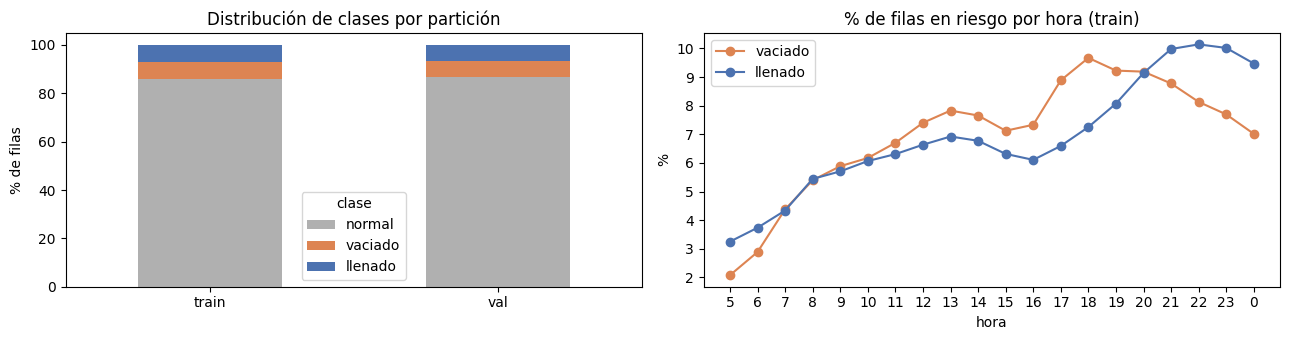

In [14]:
# Revisamos como quedaron las distribuciones de clases por partición y por hora, para ver si hay desbalanceo
dist = pd.crosstab(tabla["particion"], tabla["clase"].map(dict(enumerate(CLASES))), normalize="index").reindex(index=["train", "val"], columns=CLASES)
display((dist * 100).round(1))


fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
# Grafica de barras
(dist * 100).plot(kind="bar", stacked=True, ax=axes[0], color=["#B0B0B0", "#DD8452", "#4C72B0"], rot=0)
axes[0].set(title="Distribución de clases por partición", ylabel="% de filas", xlabel="")
por_hora_cl = pd.crosstab(tabla.loc[tabla["particion"] == "train", "hora"], tabla.loc[tabla["particion"] == "train", "clase"], normalize="index")
orden = [(h + P["hora_reinicio"]) % 24 for h in range(len(KT))]

# Grafica de puntos por hora, solo train
(por_hora_cl.reindex(orden)[[1, 2]] * 100).set_axis(["vaciado", "llenado"], axis=1).reset_index(drop=True).plot(ax=axes[1], marker="o", color=["#DD8452", "#4C72B0"])
axes[1].set(title="% de filas en riesgo por hora (train)", xlabel="hora", ylabel="%", xticks=range(len(orden)))
axes[1].set_xticklabels(orden)
plt.tight_layout()
fig.savefig(FIG / "distribucion_clases.png", dpi=150)

## 3. Modelos y métricas

### 3.1 Propuesta

| | Modelo | Idea |
|---|---|---|
| **Baseline 1** | Persistencia | ocupacion estimada ≤ a → vaciado, ≥ b → llenado. a y b se ajustan en validación. Puntaje para el ranking: max(1 − ocup, ocup) |
| **Baseline 2** | Perfil histórico | Frecuencia de cada clase por estación × día de la semana × hora en entrenamiento |
| **Candidato** | Gradient boosting multiclase (HistGradientBoostingClassifier) | Árboles con pesos por clase |


### 3.2 Métricas

La tarea es clasificación multiclase desbalanceada (la mayoría de las filas son normales) y la decisión es operativa, cada hora el equipo de rebalanceo elige qué k estaciones visitar.

| Métrica | Por qué |
|---|---|
| **Average precision (PR-AUC) por clase de riesgo** · principal | Con clases raras, la exactitud y el ROC-AUC se ven bien aunque el modelo no encuentre los casos positivos. PR-AUC se enfoca en la clase minoritaria y no depende de un umbral ([guía de scikit-learn](https://scikit-learn.org/stable/modules/model_evaluation.html#precision-recall-and-average-precision)) |
| **Recall@k y precision@k por hora** · operativa | Mide la decisión: de las estaciones que de verdad entran en riesgo en esa hora, cuántas quedan en el top-k del modelo |
| **F2 en vaciado y llenado** | Pesa más el recall que la precisión: no visitar una estación que se vacía cuesta más que una visita de más |
| **Brier score por clase** | Revisa que las probabilidades estén calibradas. El ranking top-k se arma con ellas |

In [15]:
# Separamos el dataset final en train y val, extraemos las etiquetas
train = tabla[tabla["particion"] == "train"]
val = tabla[tabla["particion"] == "val"]
y_train, y_val = train["clase"].to_numpy(), val["clase"].to_numpy()
print(f"train: {len(train):,} filas · val: {len(val):,} filas")

# Funcion para calcular métricas de desempeño de un modelo, para cada clase y F2 score
def metricas(y, proba, pred, nombre):
    out = {"modelo": nombre}
    for c in (1, 2):
        out[f"AP {CLASES[c]}"] = average_precision_score(y == c, proba[:, c])
        out[f"Brier {CLASES[c]}"] = brier_score_loss(y == c, proba[:, c])
    f2 = fbeta_score(y, pred, beta=2, labels=[1, 2], average=None)
    out["F2 vaciado"], out["F2 llenado"] = f2
    return out

# Funcion para calcular recall y precision a partir de un score, para cada dia y hora, considerando los k primeros
def top_k(df, score, k):
    # Creamos un DataFrame, con la columna riesgo (True si clase > 0) y score (probabilidad de riesgo)
    d = pd.DataFrame({"dia": df["dia"].to_numpy(), "hora": df["hora"].to_numpy(), "score": score, "riesgo": df["clase"].to_numpy() > 0})
    # Agrupamos por dia y hora, asi tenemos las estaaciones cada hora acomodadas por el score
    d["top"] = d.groupby(["dia", "hora"])["score"].rank(method="first", ascending=False) <= k
    # Cuales de los k primeros se detectaron correctamente (riesgo = True)
    d["cubiertos"] = d["top"] & d["riesgo"]
    # Contamos el total de riesgo y cubiertos por dia y hora. Nos quedamos solo con los que tienen riesgo
    g = d.groupby(["dia", "hora"])[["riesgo", "cubiertos"]].sum()
    g = g[g["riesgo"] > 0]
    return {
        f"recall@{k}": (g["cubiertos"] / g["riesgo"]).mean(),
        f"precision@{k}": (g["cubiertos"] / k).mean(),
        "eventos de riesgo cubiertos": int(g["cubiertos"].sum()),
        "eventos de riesgo totales": int(g["riesgo"].sum()),
    }

train: 3,261,440 filas · val: 568,180 filas


#### Baseline 1: persistencia (umbrales ajustados en validación)

In [16]:
# Acotamos la ocupación estimada a [0, 1] para poder usarla como score de riesgo
oc_val = val["ocup_est"].clip(0, 1).to_numpy()

def pred_persistencia(oc, a, b):
    return np.select([oc <= a, oc >= b], [1, 2], 0)

# Creamos un grid de combinaciones de umbrales a y b para vaciado y llenado
grid = [(a, b) for a in np.arange(0.05, 0.45, 0.05) for b in np.arange(0.55, 0.96, 0.05)]
# Se calcula el F2 para cada combinación de umbrales en el grid, usando la función de predicción por persistencia
# beta = 2 por que el recall es más importante que la precision en este caso
f2_grid = [fbeta_score(y_val, pred_persistencia(oc_val, a, b), beta=2, labels=[1, 2], average="macro") for a, b in grid]
# Seleccionamos el mejor par de umbrales (a, b) que maximiza el F2
A, B = grid[int(np.argmax(f2_grid))]
print(f"umbrales elegidos en validación: vaciado ≤ {A:.2f}, llenado ≥ {B:.2f} (F2 macro = {max(f2_grid):.3f})")

proba_b1 = np.column_stack([np.zeros_like(oc_val), 1 - oc_val, oc_val])
res_b1 = metricas(y_val, proba_b1, pred_persistencia(oc_val, A, B), "B1 persistencia")
res_b1 |= top_k(val, np.maximum(1 - oc_val, oc_val), P["k_visitas"])

umbrales elegidos en validación: vaciado ≤ 0.20, llenado ≥ 0.80 (F2 macro = 0.668)


#### Baseline 2: perfil histórico por estación × día de la semana × hora

In [17]:
claves = ["estacion", "dia_semana", "hora"]
# Agrupamos por estacion, dia de la semana y hora. creamos una columna para el promedio de cada clase (0, 1, 2)
perfil = pd.get_dummies(train["clase"]).astype(float).groupby([train[c] for c in claves]).mean()
perfil.columns = [0, 1, 2]
# Contamos la frecuencia de cada clase en train
global_ = np.bincount(y_train, minlength=3) / len(y_train)
# Unimos las probabilidades de cada perfil a las filas de validación, llenamos los huecos con
# La probablidad global de cada clase, y convertimos a numpy
proba_b2 = val[claves].join(perfil, on=claves)[[0, 1, 2]].fillna(dict(enumerate(global_))).to_numpy()

# la clase de riesgo con mayor probabilidad si supera tau
def pred_umbral(proba, tau):
    riesgo = proba[:, 1:].argmax(1) + 1
    return np.where(proba[:, 1:].max(1) >= tau, riesgo, 0)

taus = np.arange(0.05, 0.6, 0.025)
# Buscamoe el tau que maximiza el F2 score en validación para el modelo de perfil histórico
tau_b2 = taus[np.argmax([fbeta_score(y_val, pred_umbral(proba_b2, t), beta=2, labels=[1, 2], average="macro") for t in taus])]
res_b2 = metricas(y_val, proba_b2, pred_umbral(proba_b2, tau_b2), "B2 perfil histórico")
res_b2 |= top_k(val, proba_b2[:, 1] + proba_b2[:, 2], P["k_visitas"])

#### Candidato: gradient boosting multiclase con pesos por clase

In [18]:
%%time
modelo = HistGradientBoostingClassifier(
    max_iter=300,
    learning_rate=0.1,
    max_leaf_nodes=63,
    min_samples_leaf=200,
    l2_regularization=1.0,
    class_weight="balanced",
    early_stopping=False,
    categorical_features=[FEATURES.index("estado_est")],
    random_state=P["seed"],
)
modelo.fit(train[FEATURES], y_train)
proba_gb = modelo.predict_proba(val[FEATURES])

tau_gb = taus[np.argmax([fbeta_score(y_val, pred_umbral(proba_gb, t), beta=2, labels=[1, 2], average="macro") for t in taus])]
res_gb = metricas(y_val, proba_gb, pred_umbral(proba_gb, tau_gb), "HistGradientBoosting")
res_gb |= top_k(val, proba_gb[:, 1] + proba_gb[:, 2], P["k_visitas"])

CPU times: user 15min 15s, sys: 14.1 s, total: 15min 29s
Wall time: 1min 11s


### 3.3 Resultados en validación

In [19]:
resultados = pd.DataFrame([res_b1, res_b2, res_gb]).set_index("modelo")
resultados.round(3)

,AP vaciado,Brier vaciado,AP llenado,Brier llenado,F2 vaciado,F2 llenado,recall@20,precision@20,eventos de riesgo cubiertos,eventos de riesgo totales
modelo,,,,,,,,,,
B1 persistencia,0.631,0.256,0.619,0.247,0.663,0.674,0.361,0.713,26239,76243
B2 perfil histórico,0.280,0.057,0.329,0.050,0.479,0.507,0.231,0.425,15651,76243
HistGradientBoosting,0.756,0.072,0.758,0.064,0.722,0.738,0.405,0.798,29357,76243


### 3.4 Hallazgos

**El modelo supera a los dos baselines en todas las métricas de ranking.** Su AP es de 0.756 en vaciado y 0.758 en llenado, contra 0.63 de la persistencia y 0.28–0.33 del perfil histórico.

**La persistencia es un baseline fuerte.** El estado actual de la estación es la señal más importante: una estación con pocas bicis tiene alta probabilidad de vaciarse en las siguientes 2 horas. La ventaja del modelo viene de los features: la tendencia de la última hora, la demanda esperada para esa hora y ese día, y el historial reciente de la estación.

**El perfil histórico es débil** porque no conoce el estado de la estación en el día actual. Sabe qué tan seguido se vacía a esa hora, pero no si hoy empezó llena o vacía.

**Techo del recall@k.** El recall@20 del modelo (0.405) hay que leerlo contra lo máximo alcanzable. En validación entran en riesgo unas 41 estaciones por hora (mediana 43), y en el 90 % de las horas son más de 20, así que con 20 visitas no se pueden cubrir todas aunque el ranking fuera perfecto. El techo, calculado como el promedio por hora de min(riesgos, k) / riesgos, es de 0.534. El modelo alcanza el 76 % de ese techo, contra 68 % de la persistencia y 43 % del perfil histórico. Hay dos limitantes: la capacidad de visitas (con k = 40 el techo subiría a 0.89) y el propio ranking, que todavía deja fuera estaciones en riesgo que cabrían entre las 20 primeras. La precisión@20 (0.798) indica que unas 16 de cada 20 visitas sugeridas corresponden a estaciones que de verdad entran en riesgo.

**Impacto operativo.** Con las mismas 20 visitas por hora, el ranking del modelo cubre 29,357 situaciones de riesgo en validación, contra 26,239 de la persistencia: 3,118 más (+12 %).

**Calibración.** El Brier del modelo es peor que el del perfil histórico porque el entrenamiento usa pesos por clase, que inflan las probabilidades de vaciado y llenado. Para ordenar estaciones esto no importa, pero si las probabilidades se van a mostrar como tales, hay que calibrarlas antes.



Con estos resultados se tienen que recalcar dos puntos:
- Las métricas miden qué tan bien se predice el riesgo reconstruido a partir de los viajes, no el inventario real, que no está en los datos.
- k = 20 es un supuesto de capacidad operativa, se pueden repetir las métricas top-k con otros valores de k.


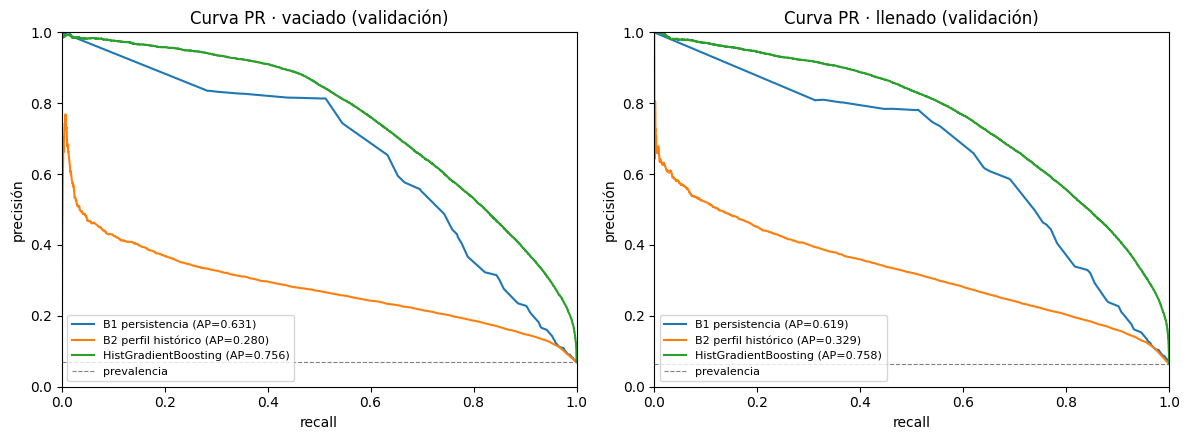

In [20]:
# Graficamos las curvas de precision-recall para cada clase y cada modelo, con el promedio de precision (AP) en la leyenda
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, c in zip(axes, (1, 2)):
    for nombre, proba in [("B1 persistencia", proba_b1), ("B2 perfil histórico", proba_b2), ("HistGradientBoosting", proba_gb)]:
        p, r, _ = precision_recall_curve(y_val == c, proba[:, c])
        ax.plot(r, p, label=f"{nombre} (AP={average_precision_score(y_val == c, proba[:, c]):.3f})")
    ax.axhline((y_val == c).mean(), ls="--", c="grey", lw=0.8, label="prevalencia")
    ax.set(title=f"Curva PR · {CLASES[c]} (validación)", xlabel="recall", ylabel="precisión", xlim=(0, 1), ylim=(0, 1))
    ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(FIG / "curvas_pr_val.png", dpi=150)

### 3.5 Registro en MLflow

Se registra un run por modelo en el experimento `mibici-equipo37`, con el mismo servidor y las mismas etiquetas que P1 y P3 (`MiBici/config.py`):

- **Parámetros:** todo `P` (rango de fechas, cortes de partición, umbrales, horizonte, resolución, k), el SHA-256 del CSV de viajes como versión de los datos, la versión de la nomenclatura y los hiperparámetros de cada modelo.
- **Métricas:** las de la tabla de validación, con prefijo `val_`.
- **Artefactos:** la distribución de clases, las curvas PR y `s0_por_estacion.csv`.
- **Etiquetas:** `equipo`, `pregunta=P2`, `git_commit`, `git_worktree_clean` y `version_datos`.

In [21]:
# Registro en MLFlow

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for bloque in iter(lambda: f.read(8 * 1024 * 1024), b""):
            h.update(bloque)
    return h.hexdigest()

def git(*args):
    return subprocess.run(["git", *args], cwd=ROOT, capture_output=True, text=True).stdout.strip()

def nombre_metrica(nombre):
    return "val_" + re.sub(r"[^a-z0-9]+", "_", nombre.lower().replace("@", "_at_")).strip("_")


mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
if mlflow.get_experiment_by_name(MLFLOW_EXPERIMENT) is None:
    MLFLOW_ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
    mlflow.create_experiment(MLFLOW_EXPERIMENT, artifact_location=MLFLOW_ARTIFACT_DIR.resolve().as_uri())
mlflow.set_experiment(MLFLOW_EXPERIMENT)

datos_sha = sha256(RAW / "mibici_2024_2025.csv")
comunes = P | {
    "datos_sha256": datos_sha,
    "estaciones_version": "nomenclatura_2026_09",
    "n_filas_train": len(train),
    "n_filas_val": len(val),
    "n_features": len(FEATURES),
}
etiquetas = {
    "equipo": "37",
    "pregunta": "P2",
    "git_commit": git("rev-parse", "HEAD") or "desconocido",
    "git_worktree_clean": str(git("status", "--porcelain") == "").lower(),
    "version_datos": datos_sha,
}
artefactos = [FIG / "distribucion_clases.png", FIG / "curvas_pr_val.png", OUT / "s0_por_estacion.csv"]
params_gb = {f"hgb_{p}": v for p, v in modelo.get_params().items() if p != "categorical_features"}

runs = [
    ("P2 - Baseline persistencia", "persistencia", res_b1, {"umbral_a": A, "umbral_b": B}),
    ("P2 - Baseline perfil histórico", "perfil_historico", res_b2, {"tau": tau_b2, "claves_perfil": ",".join(claves)}),
    ("P2 - HistGradientBoosting", "hist_gradient_boosting", res_gb, {"tau": tau_gb} | params_gb),
]
for run_name, tipo, res, params in runs:
    with mlflow.start_run(run_name=run_name) as run:
        mlflow.log_params(comunes | params)
        mlflow.set_tags(etiquetas | {"modelo": tipo})
        mlflow.log_metrics({nombre_metrica(m): float(v) for m, v in res.items() if m != "modelo"})
        for archivo in artefactos:
            mlflow.log_artifact(str(archivo), artifact_path="artefactos")
        print(f"{run_name}: run_id={run.info.run_id}")

P2 - Baseline persistencia: run_id=eef2b41bcecc4041b595a98b342158ae
P2 - Baseline perfil histórico: run_id=e8d085f7ee644defa2cd4aa2621c5dcb
P2 - HistGradientBoosting: run_id=3b1781d49ca8412788073f78ceadf08f
